3. سوالات تکلیف

3-6 تأثیر Dropout بر مقاومت به نویز در CNN روی MNIST

در شبکه‌ های عمیق، Dropout  به عنوان یک روش منظم‌ سازی (regularization) برای کاهش overfitting استفاده می‌شود. در این آزمایش، اثر نرخ‌ های مختلف Dropout را روی دقت مدل در حضور نویز گاوسی بررسی می‌کنیم.

3-6-1 معماری پایه

یک CNN ساده با دو لایه کانولوشن (۳۲ و ۶۴ فیلتر، کرنل ۳×۳، پدینگ same، پولینگ ۲×۲) و یک لایه کاملاً متصل با ۱۰ خروجی. یک لایه Dropout بعد از لایه پولینگ دوم (قبل از لایه FC) اضافه کنید. نرخ Dropout را تغییر دهید. سایر پارامترها ثابت:

•	epochs = 15

•	optimizer = Adam

•	learning rate = 0.001

•	batch size = 64

•	داده: MNIST با نویز گاوسی با انحراف معیار noise_std = 0.4

•	مقادیر مورد بررسی برای نرخ Dropout : 0، 0.2، 0.5، 0.7


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, TensorDataset, Dataset
import torchvision
from torchvision import transforms, datasets, models
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from datetime import datetime
import os
from pathlib import Path
import sys
import time
from PIL import Image
import requests
from io import BytesIO
import copy


sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data, get_mnist_data_with_noise
from plotting import plot_signals
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

In [6]:
current_dir = Path.cwd()  # .../src
data_root = current_dir.parent / 'data'  # .../data
data_root = str(data_root)

class NoisyMNIST(Dataset):
    def __init__(self, dataset, noise_std=0.4):
        self.dataset = dataset
        self.noise_std = noise_std

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        noise = torch.randn_like(img) * self.noise_std
        img_noisy = img + noise
        return img_noisy, label

# Base transform (normalization as before)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Clean datasets (for test and optional clean training)
train_clean = datasets.MNIST(root=data_root, train=True, download=False, transform=transform)
test_clean = datasets.MNIST(root=data_root, train=False, download=False, transform=transform)

# Noisy training dataset (noise_std=0.4)
train_noisy = NoisyMNIST(train_clean, noise_std=0.4)

batch_size = 64
train_loader_noisy = DataLoader(train_noisy, batch_size=batch_size, shuffle=True)
test_loader_clean = DataLoader(test_clean, batch_size=batch_size, shuffle=False)
test_loader_noisy = DataLoader(NoisyMNIST(test_clean, noise_std=0.4), batch_size=batch_size, shuffle=False)

3-6-2 برای هر نرخ  Dropout، جدول زیر را تهیه کنید:

•	دقت نهایی روی مجموعه آزمون (بدون نویز در آزمون)

•	دقت نهایی روی مجموعه آزمون با نویز مشابه (std=0.4)

•	اختلاف دقت بین داده‌های تمیز و نویزدار


In [7]:
class CNNWithDropout(nn.Module):
    def __init__(self, dropout_rate=0.5):
        super(CNNWithDropout, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding='same')
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding='same')
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(64 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


In [8]:
def train_model(model, train_loader, test_loader_clean, test_loader_noisy, epochs=20, lr=0.001):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_acc_history = []
    test_clean_acc_history = []
    test_noisy_acc_history = []

    for epoch in range(epochs):
        # Training
        model.train()
        correct_train = 0
        total_train = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
        train_acc = 100 * correct_train / total_train
        train_acc_history.append(train_acc)

        # Evaluation on clean test set
        model.eval()
        correct_clean = 0
        total_clean = 0
        with torch.no_grad():
            for images, labels in test_loader_clean:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total_clean += labels.size(0)
                correct_clean += (predicted == labels).sum().item()
        test_clean_acc = 100 * correct_clean / total_clean
        test_clean_acc_history.append(test_clean_acc)

        # Evaluation on noisy test set (same noise std as training)
        correct_noisy = 0
        total_noisy = 0
        with torch.no_grad():
            for images, labels in test_loader_noisy:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total_noisy += labels.size(0)
                correct_noisy += (predicted == labels).sum().item()
        test_noisy_acc = 100 * correct_noisy / total_noisy
        test_noisy_acc_history.append(test_noisy_acc)

        if (epoch+1) % 5 == 0:
            print(f"Epoch {epoch+1:2d}/{epochs} | Train Acc: {train_acc:.2f}% | Clean Test: {test_clean_acc:.2f}% | Noisy Test: {test_noisy_acc:.2f}%")

    return model, train_acc_history, test_clean_acc_history, test_noisy_acc_history

In [9]:
dropout_rates = [0.0, 0.2, 0.5, 0.7]
results = []

for dr in dropout_rates:
    print(f"\n===== Training with Dropout rate = {dr} =====")
    model = CNNWithDropout(dropout_rate=dr)
    model, train_accs, clean_accs, noisy_accs = train_model(
        model, train_loader_noisy, test_loader_clean, test_loader_noisy,
        epochs=20, lr=0.001
    )
    final_clean = clean_accs[-1]
    final_noisy = noisy_accs[-1]
    diff = final_clean - final_noisy
    results.append({
        'dropout': dr,
        'final_clean_acc': final_clean,
        'final_noisy_acc': final_noisy,
        'diff_clean_noisy': diff,
        'train_acc_hist': train_accs,
        'clean_acc_hist': clean_accs,
        'noisy_acc_hist': noisy_accs,
        'model': model
    })
    print(f"Final -> Clean: {final_clean:.2f}%, Noisy: {final_noisy:.2f}%, Diff: {diff:.2f}%")



===== Training with Dropout rate = 0.0 =====
Epoch  5/20 | Train Acc: 99.08% | Clean Test: 99.01% | Noisy Test: 98.84%
Epoch 10/20 | Train Acc: 99.50% | Clean Test: 99.05% | Noisy Test: 99.02%
Epoch 15/20 | Train Acc: 99.68% | Clean Test: 99.21% | Noisy Test: 99.13%
Epoch 20/20 | Train Acc: 99.76% | Clean Test: 99.13% | Noisy Test: 99.06%
Final -> Clean: 99.13%, Noisy: 99.06%, Diff: 0.07%

===== Training with Dropout rate = 0.2 =====
Epoch  5/20 | Train Acc: 98.86% | Clean Test: 99.17% | Noisy Test: 99.03%
Epoch 10/20 | Train Acc: 99.28% | Clean Test: 98.99% | Noisy Test: 98.93%
Epoch 15/20 | Train Acc: 99.48% | Clean Test: 99.20% | Noisy Test: 99.10%
Epoch 20/20 | Train Acc: 99.53% | Clean Test: 99.22% | Noisy Test: 99.12%
Final -> Clean: 99.22%, Noisy: 99.12%, Diff: 0.10%

===== Training with Dropout rate = 0.5 =====
Epoch  5/20 | Train Acc: 98.20% | Clean Test: 98.96% | Noisy Test: 98.95%
Epoch 10/20 | Train Acc: 98.76% | Clean Test: 99.25% | Noisy Test: 99.14%
Epoch 15/20 | Train 

In [10]:
df_results = pd.DataFrame([(r['dropout'], r['final_clean_acc'], r['final_noisy_acc'], r['diff_clean_noisy']) for r in results],
                          columns=['Dropout Rate', 'Test Acc (Clean)', 'Test Acc (Noisy)', 'Diff (Clean-Noisy)'])
print("\n===== Table 3-6-2: Results =====")
print(df_results.to_string(index=False))
df_results.to_csv('dropout_experiment_results.csv', index=False)



===== Table 3-6-2: Results =====
 Dropout Rate  Test Acc (Clean)  Test Acc (Noisy)  Diff (Clean-Noisy)
          0.0             99.13             99.06                0.07
          0.2             99.22             99.12                0.10
          0.5             99.38             99.11                0.27
          0.7             99.14             99.02                0.12


3-6-3 نمودار دقت آزمون در طول دوره‌ ها را برای نرخ‌ های 0.0، 0.2، 0.5 و 0.7 در یک شکل رسم کنید. کدام نرخ سریع ‌ترین همگرایی را دارد؟

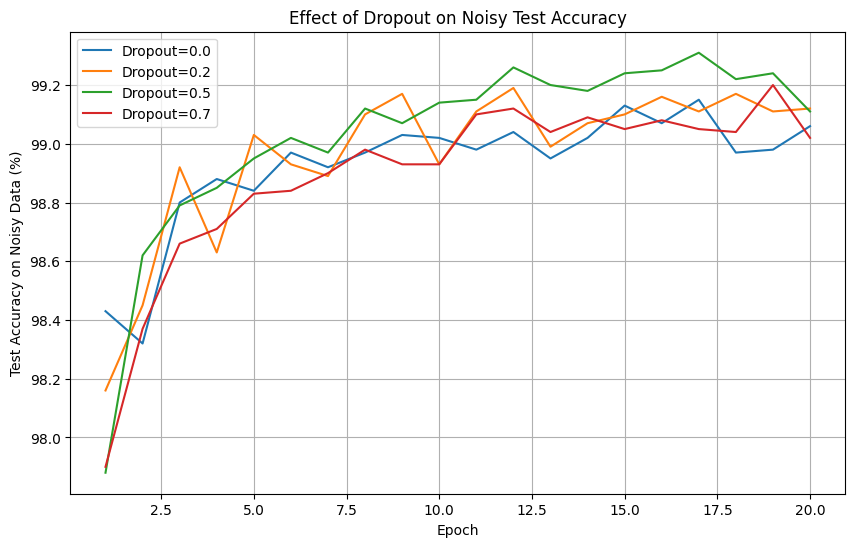

In [11]:
plt.figure(figsize=(10, 6))
for r in results:
    plt.plot(range(1, 21), r['noisy_acc_hist'], label=f"Dropout={r['dropout']}")
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy on Noisy Data (%)')
plt.title('Effect of Dropout on Noisy Test Accuracy')
plt.legend()
plt.grid(True)
plt.savefig('dropout_noisy_accuracy_curves.png', dpi=150)
plt.show()


In [ ]:
# Determine fastest convergence (epoch where noisy acc first reaches within 1% of final)
fastest_dropout = None
fastest_epoch = 20
for r in results:
    final = r['final_noisy_acc']
    for epoch_idx, acc in enumerate(r['noisy_acc_hist']):
        if acc >= final - 0.5:  # within 0.5% of final
            if epoch_idx + 1 < fastest_epoch:
                fastest_epoch = epoch_idx + 1
                fastest_dropout = r['dropout']
            break
print(f"\nFastest convergence (to within 0.5% of final noisy acc) with dropout={fastest_dropout} at epoch {fastest_epoch}")



Fastest convergence (to within 0.5% of final noisy acc) with dropout=0.0 at epoch 2


3-6-4 آیا افزایش نرخ Dropout باعث کاهش overfitting می‌شود؟ (نکته: تفاوت بین دقت آموزش و آزمون را بررسی کنید.) بهترین نرخ Dropout را از نظر بالاترین دقت روی داده نویزدار انتخاب کنید.

In [13]:
# 3-6-4: Analyze overfitting (difference between train and test on noisy)
# =====================================================
print("\n===== Overfitting Analysis =====")
for r in results:
    train_final = r['train_acc_hist'][-1]
    test_noisy_final = r['final_noisy_acc']
    gap = train_final - test_noisy_final
    print(f"Dropout {r['dropout']}: Final Train Acc = {train_final:.2f}%, Noisy Test Acc = {test_noisy_final:.2f}%, Gap = {gap:.2f}%")
    if gap < 2.0:
        print("  -> Low overfitting (good generalization)")
    elif gap < 5.0:
        print("  -> Moderate overfitting")
    else:
        print("  -> High overfitting")

best_dropout = max(results, key=lambda x: x['final_noisy_acc'])['dropout']
print(f"\nBest dropout rate for highest noisy test accuracy: {best_dropout}")



===== Overfitting Analysis =====
Dropout 0.0: Final Train Acc = 99.76%, Noisy Test Acc = 99.06%, Gap = 0.70%
  -> Low overfitting (good generalization)
Dropout 0.2: Final Train Acc = 99.53%, Noisy Test Acc = 99.12%, Gap = 0.41%
  -> Low overfitting (good generalization)
Dropout 0.5: Final Train Acc = 99.01%, Noisy Test Acc = 99.11%, Gap = -0.10%
  -> Low overfitting (good generalization)
Dropout 0.7: Final Train Acc = 98.52%, Noisy Test Acc = 99.02%, Gap = -0.50%
  -> Low overfitting (good generalization)

Best dropout rate for highest noisy test accuracy: 0.2


3-6-5 مدل را با بهترین نرخ Dropout (از قسمت قبل) روی داده بدون نویز نیز از ابتدا آموزش دهید. آیا این مدل روی داده تمیز نیز عملکرد خوبی دارد؟ جدول مقایسه ارائه دهید.

In [14]:
print(f"\n===== Training best model (dropout={best_dropout}) on CLEAN data from scratch =====")
model_best = CNNWithDropout(dropout_rate=best_dropout)
train_loader_clean = DataLoader(train_clean, batch_size=batch_size, shuffle=True)
# Train on clean data
model_best, train_acc_clean, test_clean_acc_clean_train, _ = train_model(
    model_best, train_loader_clean, test_loader_clean, test_loader_noisy,
    epochs=20, lr=0.001
)
final_clean_on_clean = test_clean_acc_clean_train[-1]
print(f"Model trained on clean data -> Test accuracy on clean: {final_clean_on_clean:.2f}%")

# Compare with previous best model (trained on noisy) evaluated on clean
best_model_trained_on_noisy = [r for r in results if r['dropout'] == best_dropout][0]
final_clean_from_noisy_train = best_model_trained_on_noisy['final_clean_acc']
print(f"Same architecture trained on noisy data -> Test accuracy on clean: {final_clean_from_noisy_train:.2f}%")

comparison_df = pd.DataFrame([
    {'Training Data': 'Noisy (std=0.4)', 'Test Data': 'Clean', 'Accuracy (%)': final_clean_from_noisy_train},
    {'Training Data': 'Clean', 'Test Data': 'Clean', 'Accuracy (%)': final_clean_on_clean}
])
print("\n===== Table 3-6-5: Comparison =====")
print(comparison_df.to_string(index=False))
comparison_df.to_csv('dropout_clean_vs_noisy_training.csv', index=False)



===== Training best model (dropout=0.2) on CLEAN data from scratch =====
Epoch  5/20 | Train Acc: 99.02% | Clean Test: 98.99% | Noisy Test: 98.34%
Epoch 10/20 | Train Acc: 99.52% | Clean Test: 99.19% | Noisy Test: 98.32%
Epoch 15/20 | Train Acc: 99.67% | Clean Test: 99.19% | Noisy Test: 97.62%
Epoch 20/20 | Train Acc: 99.71% | Clean Test: 99.25% | Noisy Test: 97.81%
Model trained on clean data -> Test accuracy on clean: 99.25%
Same architecture trained on noisy data -> Test accuracy on clean: 99.22%

===== Table 3-6-5: Comparison =====
  Training Data Test Data  Accuracy (%)
Noisy (std=0.4)     Clean         99.22
          Clean     Clean         99.25


3-6-6 یک تصویر نویزدار از آزمون انتخاب کنید و نقشه ویژگی لایه اول را برای مدل با نرخ Dropout=0 و مدل با نرخ Dropout=0.5 نمایش دهید. آیا تفاوتی در میزان نویز مشاهده شده در نقشه‌ها وجود دارد؟ تفسیر کنید.

In [15]:
# Get a noisy test image
test_loader_noisy_iter = iter(test_loader_noisy)
noisy_img, label = next(test_loader_noisy_iter)
noisy_img = noisy_img[0:1].to(device)

# Models: dropout=0 and dropout=0.5
model_drop0 = [r for r in results if r['dropout'] == 0.0][0]['model']
model_drop05 = [r for r in results if r['dropout'] == 0.5][0]['model']
model_drop0.eval()
model_drop05.eval()

def get_feature_maps_first_conv(model, x):
    with torch.no_grad():
        x = model.conv1(x)
        x = model.relu1(x)
        return x[0].cpu().numpy()  # (32, H, W)

fm0 = get_feature_maps_first_conv(model_drop0, noisy_img)   # (32, 28, 28)
fm05 = get_feature_maps_first_conv(model_drop05, noisy_img) # (32, 28, 28)


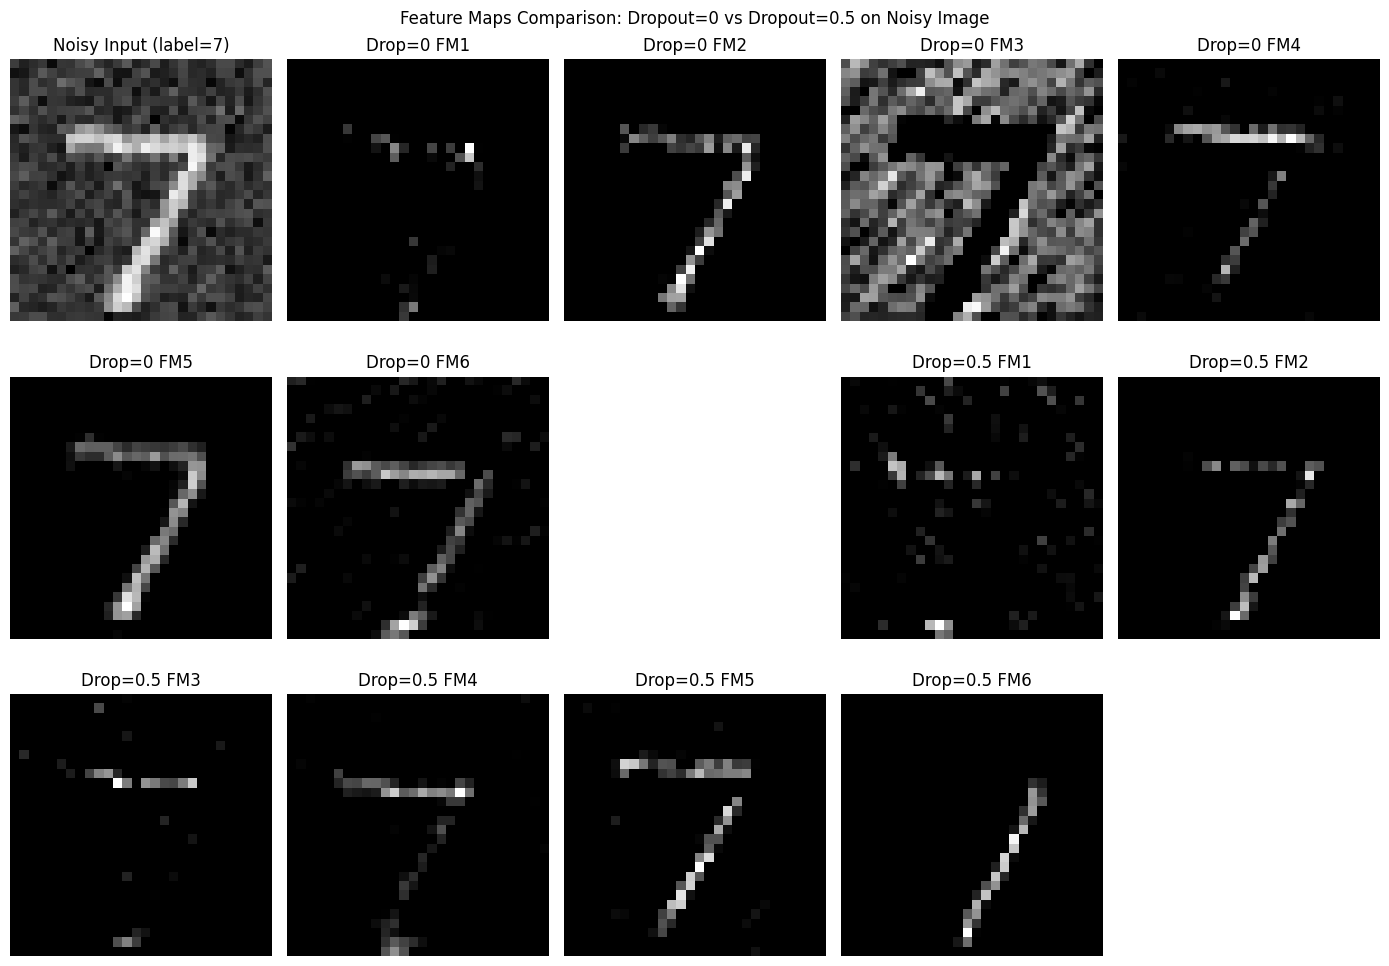

In [18]:
plt.figure(figsize=(14, 10))
# Input image
plt.subplot(3, 5, 1)
img_show = noisy_img[0,0].cpu().numpy()
plt.imshow(img_show, cmap='gray')
plt.title(f'Noisy Input (label={label[0].item()})')
plt.axis('off')
# Dropout=0 feature maps
for i in range(6):
    plt.subplot(3, 5, i+2)
    fm = fm0[i, :, :]
    fm_norm = (fm - fm.min()) / (fm.max() - fm.min() + 1e-8)
    plt.imshow(fm_norm, cmap='gray')
    plt.title(f'Drop=0 FM{i+1}')
    plt.axis('off')
# Dropout=0.5 feature maps
for i in range(6):
    plt.subplot(3, 5, i+9)
    fm = fm05[i, :, :]
    fm_norm = (fm - fm.min()) / (fm.max() - fm.min() + 1e-8)
    plt.imshow(fm_norm, cmap='gray')
    plt.title(f'Drop=0.5 FM{i+1}')
    plt.axis('off')
plt.suptitle('Feature Maps Comparison: Dropout=0 vs Dropout=0.5 on Noisy Image')
plt.tight_layout()
plt.savefig('dropout_feature_maps_comparison.png', dpi=150)
plt.show()
